# 03 · Modelo preditivo: antecipar o NPS antes da pesquisa

Este notebook atende ao item 4 do enunciado, que é opcional, e corresponde ao nível **preditivo** de pergunta analítica apresentado na Aula 1. Hoje o NPS (Net Promoter Score, ou índice de recomendação do cliente) só é conhecido depois do encerramento da jornada, e o objetivo aqui é estimar o risco de detração enquanto ainda há tempo de agir.

**Pergunta que o modelo responde:**

> **"Com os dados do pedido disponíveis antes da pesquisa, qual a chance de este cliente se tornar detrator?"**

## Estratégia

O enunciado sugere duas abordagens possíveis, e as duas foram construídas para comparação:

| Abordagem | O que entrega | Papel no projeto |
|---|---|---|
| **Classificação** (detrator: sim ou não) | Probabilidade de detração e faixa de risco (baixo, médio ou alto) | **Principal**, porque leva diretamente a uma ação, como contatar um cliente específico |
| **Regressão** (nota de 0 a 10) | Nota estimada | **Comparação**, para acompanhar tendências e simular cenários |

A classificação foi escolhida como abordagem principal por três motivos:

- **Negócio:** a operação precisa decidir quem abordar a cada dia, e uma lista priorizada por risco é mais útil para essa decisão do que uma nota estimada com casas decimais.
- **Técnico:** o NPS é calculado por categorias, e um erro de 6,5 para 7,5 na nota muda a categoria do cliente, enquanto a classificação trata essa fronteira de forma direta.
- **Detrator contra os demais, e não três classes:** como apenas 4% dos clientes são promotores, um modelo com três classes teria poucos exemplos para aprender o que caracteriza um promotor.

In [1]:
import sys
sys.path.append("..")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

from src import config
from src.data_prep import load_raw_data, prepare_dataset, calculate_nps
from src.train_model import (split_data, compare_classifiers, compare_regressors,
                             build_final_classifier, build_final_regressor,
                             evaluate_classifier, evaluate_regressor, coefficients, risk_band)
from src.viz import set_style, save

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
df = prepare_dataset(load_raw_data())

## 1. Definição da variável alvo

- **Classificação:** `is_detractor`, que vale 1 quando `nps_score` é menor que 7 e 0 nos demais casos.
- **Regressão:** `nps_score`, a nota de 0 a 10.

In [2]:
df["is_detractor"].value_counts(normalize=True).rename({1: "Detrator (1)", 0: "Não detrator (0)"}).to_frame("proporção")

,proporção
is_detractor,
Detrator (1),0.844
Não detrator (0),0.156


Como 84% dos clientes são detratores, um modelo que sempre previsse "detrator" acertaria 84% dos casos sem ter aprendido nada, e por isso a acurácia (percentual de acertos totais) não é uma métrica adequada para este problema.

A métrica principal é a **AUC (Area Under the Curve, ou área sob a curva)**, que mede a capacidade do modelo de ordenar os clientes do mais arriscado para o menos arriscado. Uma AUC de 0,5 equivale ao acaso, e uma AUC de 1,0 corresponde a uma ordenação perfeita.

## 2. Seleção e preparação das variáveis de entrada

| Decisão | Variáveis | Motivo |
|---|---|---|
| Entram no modelo | 14 variáveis de cliente, pedido, logística e atendimento | Estão disponíveis **antes** da pesquisa de NPS |
| Saem: identificadores | `customer_id`, `order_id` | Não descrevem comportamento |
| Saem: vazamento de informação | `csat_internal_score`, `repeat_purchase_30d` | São medidas junto com o NPS ou depois dele, e inflariam o desempenho |

A preparação é feita dentro de um `Pipeline` (sequência automatizada de etapas), aprendida apenas com os dados de treino:

- as variáveis numéricas passam pelo `StandardScaler`, que as coloca na mesma escala e permite comparar o peso de cada uma;
- a região passa pelo `OneHotEncoder`, que transforma cada categoria em uma coluna de 0 ou 1.

Todas as variáveis disponíveis foram mantidas, inclusive as que tiveram correlação fraca na EDA (Exploratory Data Analysis, ou análise exploratória de dados), para que o modelo confirme de forma independente o que a análise mostrou. A regularização, que penaliza pesos de variáveis pouco úteis, reduz a influência das que não ajudam.

In [3]:
print("Variáveis numéricas:", config.NUMERIC_FEATURES)
print("Variáveis categóricas:", config.CATEGORICAL_FEATURES)
print("Excluídas por vazamento:", config.LEAKAGE_COLUMNS)

Variáveis numéricas: ['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity', 'discount_value', 'payment_installments', 'delivery_time_days', 'delivery_delay_days', 'freight_value', 'delivery_attempts', 'customer_service_contacts', 'resolution_time_days', 'complaints_count']
Variáveis categóricas: ['customer_region']
Excluídas por vazamento: ['csat_internal_score', 'repeat_purchase_30d']


## 3. Lógica de separação dos dados

- Os dados foram divididos em **80% para treino e 20% para teste**, com **estratificação**, que mantém a mesma proporção de detratores nos dois conjuntos.
- No treino, foi usada a **validação cruzada de 5 dobras**, em que o modelo é treinado e avaliado 5 vezes em partes diferentes dos dados, para comparar os modelos de forma justa.
- O conjunto de **teste** foi usado **uma única vez**, no final, simulando clientes que o modelo nunca viu.
- O parâmetro `random_state=42` (semente fixa) garante que qualquer pessoa obtenha os mesmos resultados.

In [4]:
X_train, X_test, yc_train, yc_test, ys_train, ys_test = split_data(df)
print(f"Treino: {len(X_train)} pedidos ({yc_train.mean():.1%} detratores)")
print(f"Teste:  {len(X_test)} pedidos ({yc_test.mean():.1%} detratores)")

Treino: 2000 pedidos (84.4% detratores)
Teste:  500 pedidos (84.4% detratores)


## 4. Escolha do modelo de classificação

Foram comparados quatro modelos, do mais simples ao mais complexo:

- **Baseline**, um modelo de referência que sempre prevê "detrator";
- **Regressão Logística**;
- **Random Forest** (floresta aleatória), que combina muitas árvores de decisão independentes;
- **Gradient Boosting**, que combina árvores de decisão em sequência, em que cada uma corrige os erros da anterior.

In [5]:
clf_comparison = compare_classifiers(X_train, yc_train)
clf_comparison

,AUC,AUC_desvio,PR_AUC,recall,precisao,F1
modelo,,,,,,
Baseline (sempre 'detrator'),0.500,0.000,0.844,1.000,0.844,0.915
Regressão Logística,0.895,0.010,0.979,0.813,0.961,0.880
Random Forest,0.884,0.021,0.976,0.857,0.937,0.895
Gradient Boosting,0.887,0.020,0.976,0.956,0.898,0.926


O baseline tem F1 (medida que equilibra precisão e recall) de 0,915 apenas por prever "detrator" para todos, mas sua AUC de 0,5 mostra que ele não distingue nenhum cliente, o que confirma que acurácia e F1 são enganosos nesta base.

Os três modelos reais tiveram AUC entre 0,88 e 0,90, diferença que está dentro da margem de variação entre as dobras. Com desempenho equivalente, foi escolhida a **Regressão Logística**, por ser o modelo mais simples e explicável: cada variável tem um peso claro, o que facilita a apresentação às áreas de negócio e a auditoria do modelo. O parâmetro `class_weight="balanced"` faz o modelo dar a mesma atenção às duas classes.

## 5. Avaliação no conjunto de teste

In [6]:
classifier = build_final_classifier().fit(X_train, yc_train)
clf_metrics = evaluate_classifier(classifier, X_test, yc_test)
pd.Series({k: v for k, v in clf_metrics.items() if not isinstance(v, dict)}, name="teste").to_frame()

,teste
AUC,0.870
PR_AUC,0.974
recall,0.825
precisao,0.935
F1,0.877


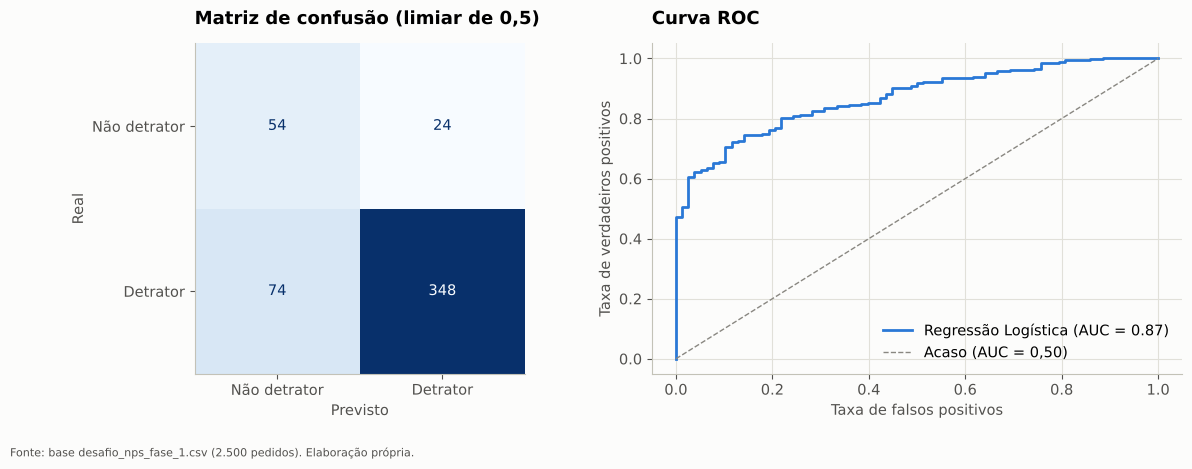

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

# Matriz de confusão: cruza a classe prevista com a classe real
ConfusionMatrixDisplay.from_estimator(classifier, X_test, yc_test, display_labels=["Não detrator", "Detrator"],
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusão (limiar de 0,5)"); axes[0].grid(False)
axes[0].set_xlabel("Previsto"); axes[0].set_ylabel("Real")

# Curva ROC: equilíbrio entre acertos e alarmes falsos em todos os limiares
proba_test = classifier.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(yc_test, proba_test)
axes[1].plot(fpr, tpr, color=config.COLOR_MAIN, linewidth=2, label=f"Regressão Logística (AUC = {clf_metrics['AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1, label="Acaso (AUC = 0,50)")
axes[1].set_xlabel("Taxa de falsos positivos"); axes[1].set_ylabel("Taxa de verdadeiros positivos")
axes[1].set_title("Curva ROC"); axes[1].legend(loc="lower right"); axes[1].grid(True)
plt.tight_layout()
save(fig, "10_avaliacao_classificador")

Os gráficos acima mostram a matriz de confusão, que cruza a classe prevista com a classe real, e a curva ROC (Receiver Operating Characteristic, ou curva de desempenho do classificador), que mostra o equilíbrio entre acertos e alarmes falsos.

Em linguagem de negócio, os resultados significam o seguinte:

- **AUC de 0,87:** ao comparar um detrator e um não detrator escolhidos ao acaso, o modelo atribui risco maior ao detrator em 87% das vezes.
- **Precisão de 0,94:** de cada 100 clientes que o modelo aponta como detratores, 94 realmente são, o que significa poucos alarmes falsos.
- **Recall (sensibilidade) de 0,83:** o modelo encontra 83% dos detratores antes da pesquisa.

### Faixas de risco para uso na operação

In [8]:
bands = pd.DataFrame(clf_metrics["faixas_risco"]).T
bands["pct_pedidos"] = 100 * bands["pedidos"] / bands["pedidos"].sum()
bands

,pedidos,pct_detratores_real,pct_pedidos
Baixo,160.000,61.300,32.000
Médio,176.000,90.900,35.200
Alto,164.000,100.000,32.800


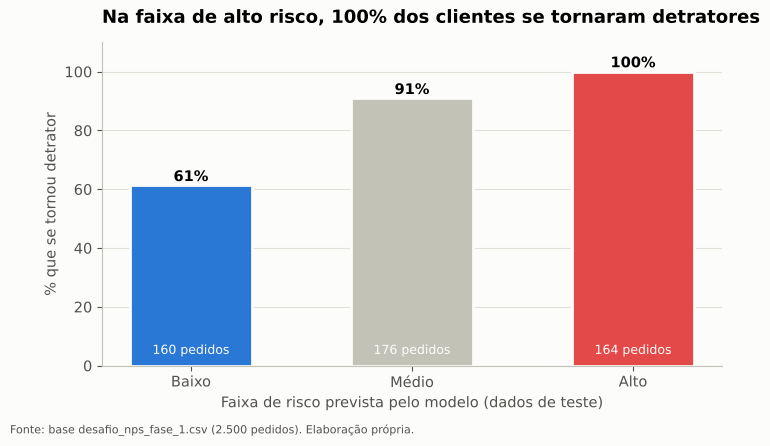

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [config.COLOR_PROMOTER, config.COLOR_CONTEXT, config.COLOR_DETRACTOR]
bars = ax.bar(bands.index, bands["pct_detratores_real"], color=colors, width=0.55, edgecolor="#fcfcfb", linewidth=2)
for bar, v, n in zip(bars, bands["pct_detratores_real"], bands["pedidos"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center", fontweight="bold")
    ax.text(bar.get_x() + bar.get_width() / 2, 4, f"{int(n)} pedidos", ha="center", color="#fcfcfb", fontsize=9)
ax.set_ylim(0, 110); ax.set_ylabel("% que se tornou detrator")
ax.set_xlabel("Faixa de risco prevista pelo modelo (dados de teste)")
ax.set_title("Na faixa de alto risco, 100% dos clientes se tornaram detratores")
save(fig, "11_faixas_risco")

O modelo divide os pedidos em três grupos de tamanho parecido, e o percentual real de detratores cresce de forma consistente entre as faixas:

| Faixa | Probabilidade prevista | % real de detratores | Ação sugerida |
|---|---|---|---|
| **Alto** | 90% ou mais | **100%** | Contato proativo em até 24 horas e compensação |
| **Médio** | de 60% a 90% | 91% | Mensagem proativa com o status da entrega e canal prioritário |
| **Baixo** | abaixo de 60% | 61% | Jornada padrão, com monitoramento |

## 6. O que o modelo aprendeu

In [10]:
coefs = coefficients(classifier)
# Peso positivo aumenta a chance de detração; peso negativo reduz
coef_table = coefs.rename(index=lambda n: config.FRIENDLY_NAMES.get(n, n.replace("customer_region_", "Região: ")))
coef_table.to_frame("peso (dados padronizados)")

,peso (dados padronizados)
Valor do pedido,-0.261
Região: Sudeste,-0.220
Região: Sul,-0.191
Tentativas de entrega,-0.128
Prazo total de entrega,-0.085
Qtd. de itens,-0.036
Parcelas,-0.012
Idade do cliente,0.006
Desconto,0.026
Região: Centro-Oeste,0.081


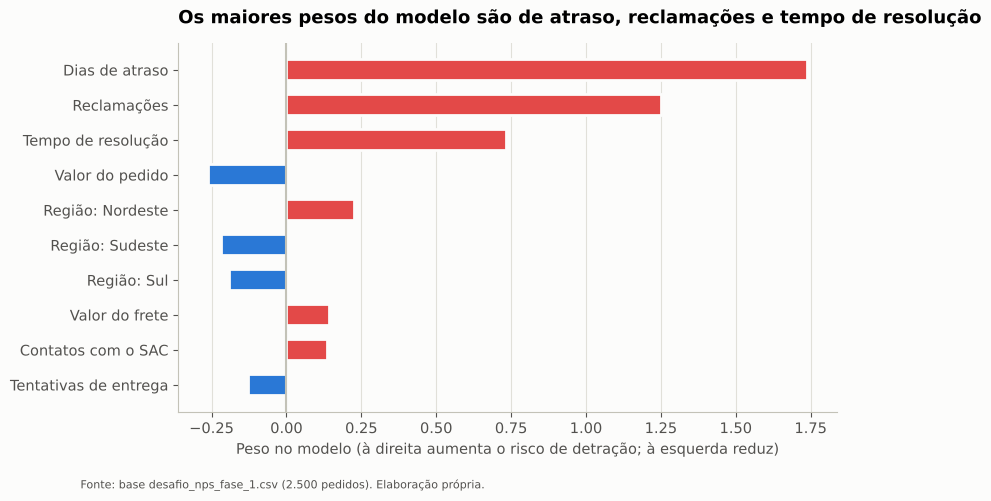

In [11]:
top = coef_table[coef_table.abs().sort_values(ascending=True).index][-10:]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [config.COLOR_DETRACTOR if v > 0 else config.COLOR_PROMOTER for v in top.values]
ax.barh(top.index, top.values, color=colors, height=0.6, edgecolor="#fcfcfb", linewidth=2)
ax.axvline(0, color="#c3c2b7"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Peso no modelo (à direita aumenta o risco de detração; à esquerda reduz)")
ax.set_title("Os maiores pesos do modelo são de atraso, reclamações e tempo de resolução")
save(fig, "12_pesos_modelo")

In [12]:
# Odds ratio (razão de chances): quanto 1 unidade a mais multiplica a chance de detração
std = X_train[config.NUMERIC_FEATURES].std()
odds_per_unit = np.exp(coefs[config.NUMERIC_FEATURES] / std).sort_values(ascending=False)
odds_per_unit.head(4).rename(index=config.FRIENDLY_NAMES).to_frame("multiplica a chance de detração por")

,multiplica a chance de detração por
Dias de atraso,3.264
Reclamações,2.007
Tempo de resolução,1.235
Contatos com o SAC,1.117


Os pesos foram convertidos em odds ratio (razão de chances), que indica quanto a chance de detração é multiplicada quando a variável aumenta em uma unidade:

- cada **dia de atraso** multiplica a chance de detração por cerca de 3, e cada **reclamação** adicional, por cerca de 2;
- quando analisados em conjunto, o **tempo de resolução** pesa mais que o **número de contatos com o SAC** (Serviço de Atendimento ao Consumidor), porque as duas variáveis andam juntas e o modelo atribui o efeito principalmente à demora na resolução;
- as variáveis de pedido, perfil e região têm pesos bem menores, o que confirma os resultados da EDA.

## 7. Comparação com o modelo de regressão

In [13]:
reg_comparison = compare_regressors(X_train, ys_train)
reg_comparison

,MAE,RMSE,R2
modelo,,,
Baseline (média),2.067,2.521,-0.002
Regressão Linear,1.319,1.670,0.560
Gradient Boosting,1.327,1.672,0.558


In [14]:
regressor = build_final_regressor().fit(X_train, ys_train)
reg_metrics = evaluate_regressor(regressor, X_test, ys_test)
baseline_mae = np.abs(ys_test - ys_train.mean()).mean()
print(f"Erro médio (MAE) do modelo:          {reg_metrics['MAE']:.2f} ponto")
print(f"Erro médio prevendo sempre a média:  {baseline_mae:.2f} pontos")
print(f"R²: {reg_metrics['R2']:.2f}  (o modelo explica cerca de {reg_metrics['R2']:.0%} da variação das notas)")

Erro médio (MAE) do modelo:          1.35 ponto
Erro médio prevendo sempre a média:  2.00 pontos
R²: 0.52  (o modelo explica cerca de 52% da variação das notas)


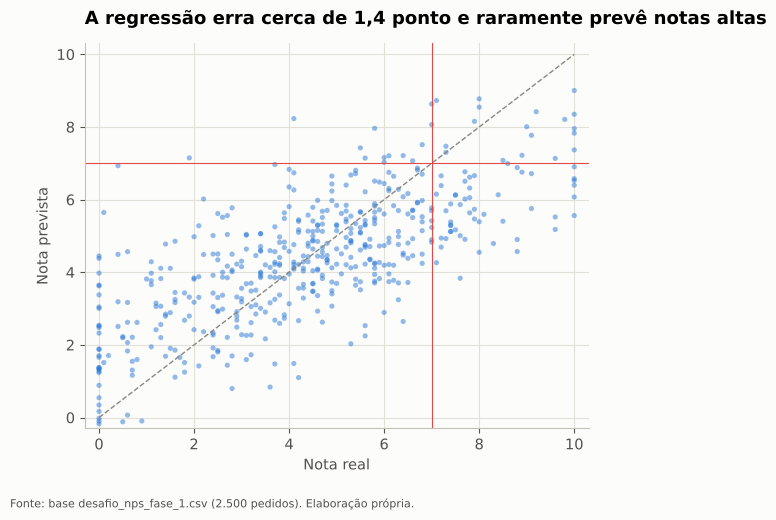

In [15]:
pred_score = regressor.predict(X_test)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(ys_test, pred_score, s=14, alpha=0.5, color=config.COLOR_MAIN, edgecolor="none")
ax.plot([0, 10], [0, 10], color="#898781", linestyle="--", linewidth=1)
ax.axvline(7, color=config.COLOR_DETRACTOR, linewidth=0.8); ax.axhline(7, color=config.COLOR_DETRACTOR, linewidth=0.8)
ax.set_xlabel("Nota real"); ax.set_ylabel("Nota prevista"); ax.grid(True)
ax.set_xlim(-0.3, 10.3); ax.set_ylim(-0.3, 10.3)
ax.set_title("A regressão erra cerca de 1,4 ponto e raramente prevê notas altas")
save(fig, "13_regressao_real_vs_previsto")

A regressão teve MAE (Mean Absolute Error, ou erro absoluto médio) de **1,4 ponto**, contra 2,0 de um modelo que sempre prevê a média, e R² (coeficiente de determinação) de **0,52**, ou seja, explica cerca de 52% da variação das notas. Ela tende a aproximar as previsões da média e raramente prevê notas acima de 9, porque há poucos promotores na base para o modelo aprender.

Por isso, a regressão é útil para acompanhar tendências e simular cenários, enquanto a classificação é mais adequada para a decisão do dia a dia sobre quem abordar.

| Critério | Classificação | Regressão |
|---|---|---|
| Pergunta | "Vai ser detrator?" | "Qual será a nota?" |
| Uso | Priorizar contatos | Projetar a tendência do NPS |
| Desempenho | AUC de 0,87 e precisão de 94% | MAE de 1,4 e R² de 0,52 |
| Recomendação | **Principal** | Complementar |

## 8. Simulação de impacto: quanto o NPS melhora com menos atraso?

A simulação é baseada nos próprios dados históricos: cada pedido recebe a taxa de detratores e de promotores observada em pedidos com o **mesmo nível de reclamações** e com o **atraso definido no cenário**.

In [16]:
df["promoter"] = (df["nps_category"] == "Promotor").astype(int)
df["atraso_grupo"] = df["delivery_delay_days"].clip(upper=4)          # 4 representa "4 dias ou mais"
df["reclamacao_grupo"] = df["faixa_reclamacoes"].astype(str)
reference = df.groupby(["atraso_grupo", "reclamacao_grupo"]).agg(
    p_det=("is_detractor", "mean"), p_pro=("promoter", "mean"))

def simulate(max_delay=None, max_complaint_band=None):
    scenario = df[["atraso_grupo", "reclamacao_grupo"]].copy()
    if max_delay is not None:
        scenario["atraso_grupo"] = scenario["atraso_grupo"].clip(upper=max_delay)
    if max_complaint_band is not None:
        order = ["0-1", "2-3", "4-5", "6+"]
        limit = order.index(max_complaint_band)
        scenario["reclamacao_grupo"] = scenario["reclamacao_grupo"].map(lambda b: order[min(order.index(b), limit)])
    rates = scenario.join(reference, on=["atraso_grupo", "reclamacao_grupo"])
    return pd.Series({"% detratores": 100 * rates["p_det"].mean(),
                      "% promotores": 100 * rates["p_pro"].mean(),
                      "NPS": 100 * (rates["p_pro"].mean() - rates["p_det"].mean())})

scenarios = pd.DataFrame({
    "Situação atual": simulate(),
    "Atraso máximo de 1 dia": simulate(max_delay=1),
    "Atraso máx. 1 dia + até 3 reclamações": simulate(max_delay=1, max_complaint_band="2-3"),
    "Nenhum atraso": simulate(max_delay=0),
}).T.round(1)
scenarios

,% detratores,% promotores,NPS
Situação atual,84.400,4.400,-80.000
Atraso máximo de 1 dia,73.600,7.600,-66.000
Atraso máx. 1 dia + até 3 reclamações,55.900,14.800,-41.100
Nenhum atraso,64.900,11.600,-53.300


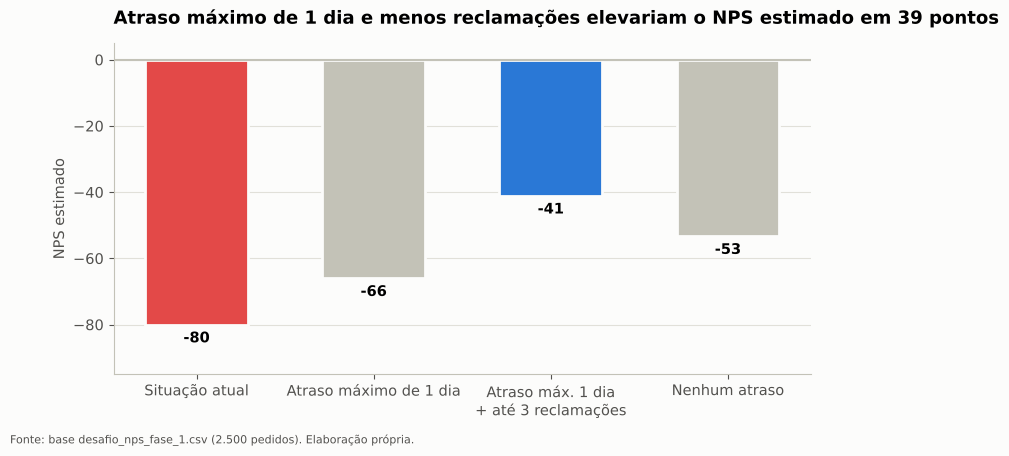

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.3))
colors = [config.COLOR_DETRACTOR, config.COLOR_CONTEXT, config.COLOR_PROMOTER, config.COLOR_CONTEXT]
bars = ax.bar([s.replace(" + ", "\n+ ") for s in scenarios.index], scenarios["NPS"], color=colors, width=0.58,
              edgecolor="#fcfcfb", linewidth=2)
for bar, v in zip(bars, scenarios["NPS"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v - 2, f"{v:.0f}", ha="center", va="top", fontweight="bold")
ax.axhline(0, color="#c3c2b7"); ax.set_ylim(-95, 5); ax.set_ylabel("NPS estimado")
ax.set_title("Atraso máximo de 1 dia e menos reclamações elevariam o NPS estimado em 39 pontos")
save(fig, "14_simulacao_cenarios")

Os resultados da simulação foram os seguintes:

- com **atraso máximo de 1 dia**, o NPS passaria de -80 para cerca de **-66**, um ganho de 14 pontos;
- **sem nenhum atraso**, o NPS chegaria a cerca de **-53**, um ganho de 27 pontos;
- com **atraso máximo de 1 dia e no máximo 3 reclamações**, o NPS chegaria a cerca de **-41**, um ganho de 39 pontos.

O cenário combinado supera o cenário sem nenhum atraso, o que indica que atuar sobre a logística e o atendimento ao mesmo tempo tem efeito maior do que concentrar todo o esforço apenas no atraso.

> Esta é uma **estimativa baseada em correlação**, e não uma garantia. O efeito real precisa ser validado com um **teste piloto**, por exemplo em uma região ou com uma transportadora.

## 9. Como a solução pode ser usada na prática

O script `src/predict.py` calcula o risco de novos pedidos e gera uma lista priorizada:

In [18]:
# Salva os modelos treinados (mesmo resultado de `python -m src.train_model`)
config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(classifier, config.CLASSIFIER_PATH)
joblib.dump(regressor, config.REGRESSOR_PATH)

from src.predict import score_orders
scored = score_orders(df)
scored.to_csv(config.SCORED_DATA_PATH, index=False)
# Observação: aqui a base inteira é pontuada apenas como demonstração; em produção, seriam os pedidos novos do dia
scored.head(8)

,customer_id,order_id,prob_detrator,faixa_risco,nota_estimada,principal_motivo,acao_sugerida
1943,1944,51944,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
461,462,50462,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
1762,1763,51763,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
1317,1318,51318,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
595,596,50596,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
1045,1046,51046,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
2050,2051,52051,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...
1597,1598,51598,1.000,Alto,0.000,Atraso na entrega,Contato proativo em até 24h + compensação (cup...


In [19]:
scored["faixa_risco"].value_counts().reindex(["Alto", "Médio", "Baixo"]).to_frame("pedidos")

,pedidos
faixa_risco,
Alto,897
Médio,742
Baixo,861


### Fluxo proposto na operação

```
Pedido despachado ─► Dados de logística e de atendimento atualizados diariamente
                          │
                          ▼
              Modelo calcula o risco de detração
                          │
        ┌─────────────────┼─────────────────┐
        ▼                 ▼                 ▼
     ALTO (≥90%)     MÉDIO (60-90%)     BAIXO (<60%)
  Ligação em 24h    Mensagem proativa   Jornada padrão
  + compensação     + canal prioritário
                          │
                          ▼
      Pesquisa NPS ─► comparação entre previsto e real ─► retreino mensal
```

Cada área usaria a solução de uma forma:

- **Experiência do Cliente e SAC:** lista diária de clientes de alto risco para contato proativo.
- **Logística:** painel com os pedidos em risco por transportadora e por rota.
- **Liderança:** NPS projetado da semana, antes da aplicação da pesquisa.

### Cuidados e limitações

1. **Correlação não é causa:** as ações devem ser validadas com um teste A/B (comparação entre um grupo que recebe a mudança e outro que não recebe) antes de serem ampliadas.
2. **Indícios de base simulada:** algumas relações são muito regulares, como a recompra de 0% e de 100%, e em dados reais o desempenho tende a ser menor.
3. **Momento da previsão:** reclamações e contatos acontecem ao longo da jornada, e o risco deve ser recalculado a cada atualização dos dados.
4. **Monitoramento:** o resultado previsto deve ser comparado com o real todos os meses, e o modelo deve ser retreinado se a AUC cair abaixo de 0,80.
5. **Uso ético:** a pontuação de risco serve para ajudar o cliente, e nunca para tratá-lo de forma pior ou para punir colaboradores.

In [20]:
# Salva as métricas finais para o relatório
metrics = {
    "comparacao_classificadores_cv": clf_comparison.reset_index().to_dict(orient="records"),
    "comparacao_regressores_cv": reg_comparison.reset_index().to_dict(orient="records"),
    "classificador_teste": clf_metrics,
    "regressor_teste": reg_metrics,
    "baseline_regressor_teste_MAE": round(float(baseline_mae), 3),
    "simulacao_cenarios": scenarios.reset_index(names="cenario").to_dict(orient="records"),
}
config.METRICS_PATH.write_text(json.dumps(metrics, indent=2, ensure_ascii=False))
print("Métricas salvas em", config.METRICS_PATH.relative_to(config.ROOT_DIR))

Métricas salvas em reports/metricas_modelo.json


## Glossário

| Termo | Significado |
|---|---|
| A/B (teste A/B) | Comparação entre um grupo que recebe uma mudança e outro que não recebe. |
| Acurácia | Percentual de acertos totais do modelo; nesta base é enganosa, porque prever "detrator" para todos já acerta 84%. |
| AUC (Area Under the Curve) | Mede se o modelo ordena bem os clientes por risco; 0,5 equivale ao acaso e 1,0 a acerto perfeito. |
| Baseline | Modelo de referência mais simples possível, usado para verificar se o modelo real aprendeu algo. |
| Classificação | Tipo de modelo que prevê uma categoria, como detrator ou não detrator. |
| EDA (Exploratory Data Analysis) | Análise exploratória de dados. |
| Estratificação | Separação dos dados que mantém a mesma proporção de cada classe em treino e teste. |
| F1 | Medida que equilibra precisão e recall. |
| Gradient Boosting | Modelo que combina árvores de decisão em sequência, em que cada uma corrige a anterior. |
| MAE (Mean Absolute Error) | Erro médio do modelo de regressão, na mesma unidade da nota. |
| Matriz de confusão | Tabela que cruza a classe prevista com a classe real, mostrando acertos e erros. |
| NPS (Net Promoter Score) | Percentual de promotores menos o percentual de detratores; varia de -100 a +100. |
| Odds ratio (razão de chances) | Quanto a chance de um evento é multiplicada quando uma variável aumenta em uma unidade. |
| OneHotEncoder | Transformação que converte cada categoria em uma coluna de 0 ou 1. |
| Pipeline | Sequência automatizada de etapas de preparação dos dados e de modelagem. |
| Precisão | Percentual de clientes apontados como detratores que realmente são detratores. |
| R² (coeficiente de determinação) | Proporção da variação das notas que o modelo explica, de 0 a 1. |
| Random Forest | Modelo que combina muitas árvores de decisão independentes e usa a votação entre elas. |
| random_state | Semente fixa que garante os mesmos resultados a cada execução. |
| Recall (sensibilidade) | Percentual de detratores reais que o modelo conseguiu identificar. |
| Regressão | Tipo de modelo que prevê um número, como a nota de 0 a 10. |
| Regressão Logística | Modelo de classificação que calcula uma probabilidade e mostra o peso de cada variável. |
| Regularização | Penalidade que reduz o peso de variáveis pouco úteis no modelo. |
| ROC (Receiver Operating Characteristic) | Curva que mostra o equilíbrio entre acertos e alarmes falsos em todos os limiares de decisão. |
| SAC (Serviço de Atendimento ao Consumidor) | Canal de atendimento ao cliente. |
| StandardScaler | Transformação que padroniza as variáveis numéricas para média 0 e desvio padrão 1. |
| Validação cruzada | Técnica que treina e avalia o modelo várias vezes em partes diferentes dos dados de treino. |
| Vazamento de informação (*data leakage*) | Uso, no modelo, de um dado que só existe depois do resultado, o que infla o desempenho. |